In [21]:
%load_ext autoreload

%autoreload 2
%reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
from pathlib import Path

print(Path.cwd().parent)

c:\Users\huber\Documents\GitHub\bank_marketing_ml


In [23]:

import pandas as pd
import matplotlib.pyplot as plt
import sys
import importlib
from pathlib import Path

ROOT_DIR = Path.cwd().parent
sys.path.append(str(ROOT_DIR))

import src.visualization

importlib.reload(src.visualization)

from src.visualization import (
    plot_target_distribution,
    plot_confusion_matrix,
    heatmap_features,
    plot_model_metrics
)

df = pd.read_csv(
    ROOT_DIR / "data/raw/bank-additional-full.csv",
    sep=";"
)

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
import seaborn as sns

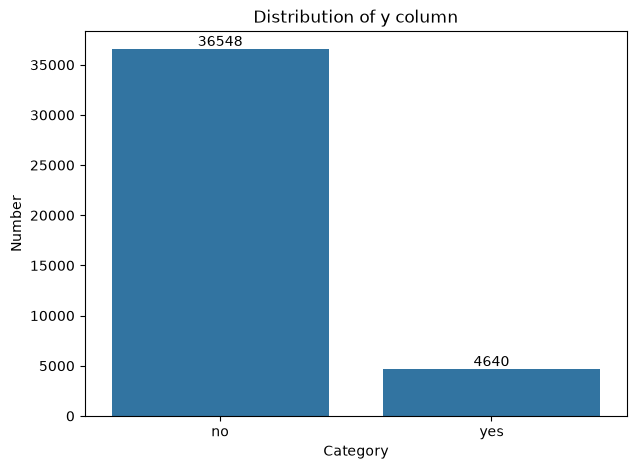

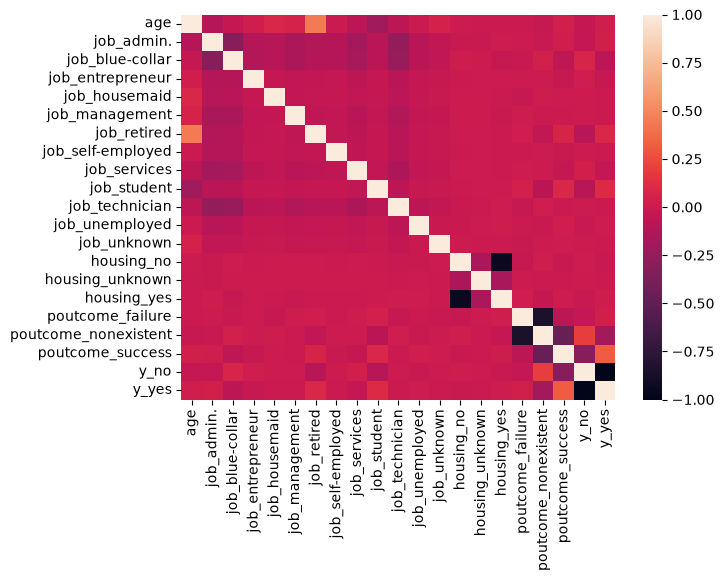

In [25]:
df.columns
diff = df[['age','job','housing','poutcome','y']]
X = diff.drop('y',axis=1)
y = diff['y']


plot_target_distribution(df,"y")
heatmap_features(diff)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y,shuffle=True
)

numeric_featrues=['age']
categorical_featrues=['job','housing','poutcome']

In [26]:
numeric_pipe = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="constant")),
    ("encoder",OneHotEncoder(handle_unknown='ignore'))
])

In [27]:
preprocces = ColumnTransformer(
    transformers=[("num",numeric_pipe,numeric_featrues),
                  ("cat",categorical_pipeline,categorical_featrues)],
)


In [ ]:

from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.tree import DecisionTreeClassifier
import seaborn as sns
import matplotlib.pyplot as plt

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

result = pd.DataFrame()

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor",preprocces),
        ("model",model)
        ])
    
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    cm=classification_report(y_test,y_pred,output_dict=True,)['yes']
    #print(classification_report(y_test, y_pred,zero_division=0)) 
    
    print("Name of algorithm :")
    print(name)     
    #cm1 = confusion_matrix(y_val,y_pred)
    #plot_confusion_matrix(cm1,name)

    result[name] ={
        "prec" : cm["precision"],
        "f1" : cm["f1-score"],
        "recall" : cm["recall"]
    }

print(result)


Name of algorithm :
Logistic Regression
Name of algorithm :
Random Forest
Name of algorithm :
Gradient Boosting
Name of algorithm :
Decision Tree
        Logistic Regression  Random Forest  Gradient Boosting  Decision Tree
prec               0.682051       0.543269           0.678756       0.562842
f1                 0.298541       0.250000           0.294713       0.234357
recall             0.191092       0.162356           0.188218       0.147989


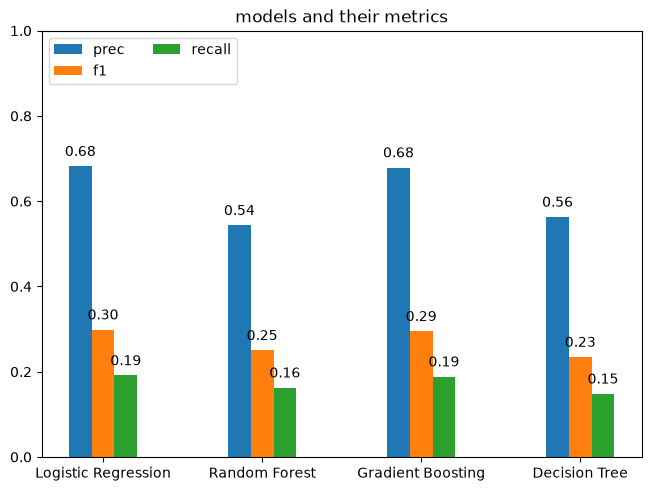

In [38]:
plot_model_metrics(result)